# Exploración inicial de la supervivencia en el Titanic

**MCDI503 · Exploración Inteligente para la Ciencia de Datos — Avance del Proyecto, Fase 1 (Evaluación Sumativa 1)**

## I. Identificación del proyecto

| Campo | Detalle |
|---|---|
| Título del avance | Exploración inicial de la supervivencia en el Titanic |
| Equipo | Grupo 10 |
| Integrantes | José Ignacio Rodríguez Cisternas · Sebastian Andrés Rojas Araya · Yerko Gallardo Miranda |
| Docente | Sergio Paraíso Medina |
| Fecha | Noviembre de 2026 |
| Conjunto de datos | `titanic`, repositorio de datos de ejemplo de seaborn, cargado con `seaborn.load_dataset("titanic")` (891 pasajeros × 15 variables) |
| Propósito general | Implementar un primer ciclo de análisis exploratorio (EDA) reproducible y documentado que caracterice la calidad de los datos y describa cómo se distribuye la supervivencia observada según atributos de los pasajeros. |

**Cómo leer este notebook.** Las secciones siguen el flujo del EDA: contexto → carga → exploración → decisiones → resultados → supuestos → cierre. Cada bloque de código va precedido de una celda que indica *qué pregunta atiende, qué se hace y por qué*, y seguido de una interpretación del resultado. Las tablas y figuras están numeradas por sección (Tabla 3.1, Figura 3.1, …) para referenciarlas desde el informe PDF. Las decisiones exploratorias se identifican como **D1, D2, …** y se consolidan en la sección V.

**Cómo reproducirlo.** Desde la raíz del repositorio: `uv sync` y luego `uv run jupyter nbconvert --to notebook --execute --inplace sumativa1/mcdi503_f1_sumativo_grupo10.ipynb` (o *Restart & Run All* en Jupyter/VS Code). Las versiones exactas de las librerías están fijadas en `uv.lock`.

## II. Contexto y objetivo exploratorio

### II.1 Contexto del problema

El 15 de abril de 1912 el RMS *Titanic* se hundió en su viaje inaugural entre Southampton y Nueva York. Murieron más de 1.500 de las aproximadamente 2.200 personas a bordo. Los botes salvavidas no alcanzaban para todos, y la evacuación se rigió en buena medida por el criterio de «mujeres y niños primero» y por el acceso a cubierta, que dependía de la clase del pasaje. Por eso la supervivencia no se distribuyó al azar entre los pasajeros.

El conjunto de datos `titanic` de seaborn registra **un pasajero por fila** (unidad de observación) con su resultado (`survived`), atributos sociodemográficos (`sex`, `age`, `who`), de viaje (`pclass`, `fare`, `embarked`, `deck`) y de grupo familiar (`sibsp`, `parch`, `alone`). Corresponde a 891 de los pasajeros y no incluye a la tripulación. Es el subconjunto de entrenamiento difundido por Kaggle a partir de registros históricos del pasaje.

**Problema que motiva la exploración.** Antes de cualquier modelamiento, hay que saber si los datos son confiables para estudiar la supervivencia y qué patrones descriptivos muestran. Hay faltantes, variables redundantes y registros sin identificador, que pueden sesgar cualquier conclusión si no se diagnostican primero.

**Valor del análisis.** El EDA documentado permite: (a) decidir con evidencia cómo tratar faltantes, duplicados y redundancias en las fases siguientes, (b) identificar los grupos (sexo, clase) con mayor y menor supervivencia observada como base para hipótesis posteriores, y (c) dejar una línea base reproducible que el equipo pueda ampliar sin rehacer el trabajo.

### II.2 Objetivo exploratorio del avance

> Caracterizar la estructura y la calidad del conjunto de datos `titanic` y describir cómo se distribuyen la edad, la tarifa y la supervivencia observada según sexo y clase. Cada decisión exploratoria debe quedar documentada y el flujo debe ser reproducible de principio a fin.

### II.3 Preguntas exploratorias iniciales

| Id | Pregunta | Evidencia esperada | Dónde se trabaja |
|---|---|---|---|
| **P1** | ¿Qué problemas de calidad presentan las variables clave y cómo condicionan el análisis? | Tabla de tipos, faltantes, valores fuera de dominio y repetidos, con decisiones justificadas | III.4 (diagnóstico) → V (decisiones) → VI (respuesta) |
| **P2** | ¿Cómo se distribuyen la edad y la tarifa? | Estadísticos descriptivos y gráficos, informando el número de observaciones válidas | IV → VI |
| **P3** | ¿Cómo varía la supervivencia observada según sexo y clase? | Pasajeros, sobrevivientes y tasa por grupo, incluido el cruce sexo × clase | IV → VI |

### II.4 Alcance y supuestos iniciales

- **Alcance:** primer ciclo de EDA, de carácter **descriptivo**. Abarca la carga, el diagnóstico de calidad, el análisis univariado de edad y tarifa, el bivariado de supervivencia según sexo y clase, y transformaciones básicas. No incluye modelos predictivos, pruebas de hipótesis ni imputación avanzada.
- **S1.** Cada fila corresponde a un pasajero distinto, aunque el dataset no trae un identificador (sin nombre, ticket ni `PassengerId`).
- **S2.** Los 891 registros son una **muestra** del pasaje, no el total a bordo. Las tasas describen esta muestra y no se generalizan sin cautela.
- **S3.** Las diferencias entre grupos se interpretan como **asociaciones descriptivas**, no como efectos causales.
- **S4.** Los valores registrados son correctos salvo evidencia de error (fuera de dominio o inconsistentes).

### II.5 Pertinencia del dataset elegido

Se eligió `titanic` sobre `mpg` y `penguins` (**D1**) porque es el único de los tres que permite cubrir todo el recorrido técnico pedido en la fase:
- tiene faltantes en distintas magnitudes (2, 177 y 688 registros);
- tiene variables numéricas y categóricas;
- tiene columnas redundantes y derivadas que hay que verificar;
- tiene registros repetidos sin identificador;
- tiene una variable de resultado binaria que permite el análisis bivariado y por subgrupos.

## III. Carga y revisión inicial de datos

### III.1 Configuración del entorno

**Qué y por qué.** Se importan las librerías y se registran las versiones de Python y de cada paquete, para que cualquier diferencia de resultados pueda atribuirse a una diferencia de entorno. Las rutas son relativas a la carpeta del notebook. Se fija una semilla para que eventuales muestreos posteriores sean repetibles.

In [1]:
import hashlib
import platform
import shutil
import sys
from datetime import datetime
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

SEED = 42
np.random.seed(SEED)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 120)
pd.set_option("display.float_format", "{:.2f}".format)
sns.set_theme(style="whitegrid", context="notebook")

# Rutas relativas: funciona si el kernel arranca en sumativa1/ o en la raíz del repositorio
BASE_DIR = Path.cwd() if (Path.cwd() / "docs").exists() else Path.cwd() / "sumativa1"
RAW_DIR = BASE_DIR / "data" / "raw"
RAW_DIR.mkdir(parents=True, exist_ok=True)

entorno = pd.DataFrame(
    {
        "componente": ["Python", "Sistema", "pandas", "numpy", "matplotlib", "seaborn", "Ejecución"],
        "versión": [
            platform.python_version(),
            platform.platform(terse=True),
            pd.__version__,
            np.__version__,
            matplotlib.__version__,
            sns.__version__,
            datetime.now().strftime("%Y-%m-%d %H:%M"),
        ],
    }
)
entorno

,componente,versión
0,Python,3.14.4
1,Sistema,Windows-11
2,pandas,3.1.1
3,numpy,2.5.5
4,matplotlib,3.11.2
5,seaborn,0.13.2
6,Ejecución,2026-11-23 21:21


*Tabla 3.1 — Entorno de ejecución.* Las versiones mostradas coinciden con las fijadas en `uv.lock`. Si otra persona ejecuta el notebook con versiones distintas, esta tabla lo deja en evidencia.

### III.2 Carga del conjunto de datos

**Qué y por qué.** El dataset se obtiene programáticamente con `sns.load_dataset("titanic")`, como indicó el docente. Esta función descarga el CSV del repositorio público `mwaskom/seaborn-data` y lo guarda en la caché local de seaborn. Como la fuente remota podría cambiar, se toman dos medidas de reproducibilidad:

- **D2.** Se calcula la huella **SHA-256** del archivo descargado y se compara con la registrada en la primera ejecución. También se guarda una copia congelada byte a byte en `data/raw/titanic_seaborn.csv`. Si la fuente cambia, el notebook lo advierte en vez de producir resultados distintos en silencio.
- **D3.** Los datos originales se conservan intactos en `df_raw`. Toda transformación posterior trabaja sobre la copia `df`, de modo que siempre es posible volver al estado de entrada.

In [2]:
DATASET = "titanic"
SHA256_ESPERADO = "81787d320d7f7b03df935e91de8bd19e11d45c5bbcab86ef4d4a76dc91b7d4f2"  # registrado el 2026-11-23
FORMA_ESPERADA = (891, 15)

df_raw = sns.load_dataset(DATASET)  # descarga (o lee desde caché) el CSV de seaborn-data

# Huella del archivo fuente tal como lo entrega seaborn
archivo_fuente = Path(sns.get_data_home()) / f"{DATASET}.csv"
sha256 = hashlib.sha256(archivo_fuente.read_bytes()).hexdigest()

# Copia congelada byte a byte para trazabilidad
copia_raw = RAW_DIR / "titanic_seaborn.csv"
shutil.copyfile(archivo_fuente, copia_raw)

print(f"Fuente            : https://github.com/mwaskom/seaborn-data/blob/master/{DATASET}.csv")
print(f"Caché seaborn     : {archivo_fuente.name} ({archivo_fuente.stat().st_size:,} bytes)")
print(f"Copia congelada   : {copia_raw.relative_to(BASE_DIR)}")
print(f"SHA-256 obtenido  : {sha256}")
print(f"Coincide huella   : {sha256 == SHA256_ESPERADO}")
print(f"Dimensiones       : {df_raw.shape}  (esperadas {FORMA_ESPERADA})")

assert df_raw.shape == FORMA_ESPERADA, "Las dimensiones no coinciden con las registradas: revisar la fuente."
assert sha256 == SHA256_ESPERADO, "La fuente remota cambió respecto de la versión registrada: revisar antes de continuar."

df = df_raw.copy()  # D3: copia de trabajo; df_raw no se modifica en ningún punto del notebook

Fuente            : https://github.com/mwaskom/seaborn-data/blob/master/titanic.csv
Caché seaborn     : titanic.csv (57,018 bytes)
Copia congelada   : data\raw\titanic_seaborn.csv
SHA-256 obtenido  : 81787d320d7f7b03df935e91de8bd19e11d45c5bbcab86ef4d4a76dc91b7d4f2
Coincide huella   : True
Dimensiones       : (891, 15)  (esperadas (891, 15))


**Resultado.** La huella coincide con la registrada y las dimensiones son 891 × 15. Los datos de entrada son exactamente los mismos en cada ejecución, y cualquier cambio en la fuente detiene el notebook con un mensaje explícito.

### III.3 Estructura del conjunto de datos

**Qué y por qué.** Se revisan las primeras filas, los tipos de datos y el significado de cada variable. Así se confirma la unidad de observación (un pasajero por fila) y se asigna un rol a cada columna antes de explorarla.

In [3]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.00,1,0,7.25,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.00,1,0,71.28,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.00,0,0,7.92,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.00,1,0,53.10,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.00,0,0,8.05,S,Third,man,True,NaN,Southampton,no,True


*Tabla 3.2 — Primeras cinco filas del dataset.*

In [4]:
descripcion = {
    "survived": ("Sobrevivió (0 = no, 1 = sí)", "Objetivo"),
    "pclass": ("Clase del pasaje (1, 2, 3)", "Explicativa"),
    "sex": ("Sexo del pasajero", "Explicativa"),
    "age": ("Edad en años", "Explicativa"),
    "sibsp": ("N.º de hermanos/cónyuges a bordo", "Explicativa"),
    "parch": ("N.º de padres/hijos a bordo", "Explicativa"),
    "fare": ("Tarifa pagada (libras esterlinas)", "Explicativa"),
    "embarked": ("Puerto de embarque (C, Q, S)", "Explicativa"),
    "class": ("Clase del pasaje en texto", "Redundante con pclass"),
    "who": ("Categoría: man / woman / child", "Derivada de sex y age"),
    "adult_male": ("Hombre adulto (bool)", "Derivada de who"),
    "deck": ("Cubierta del camarote (A–G)", "Explicativa"),
    "embark_town": ("Ciudad de embarque", "Redundante con embarked"),
    "alive": ("Sobrevivió (no / yes)", "Redundante con survived"),
    "alone": ("Viaja solo (sibsp + parch = 0)", "Derivada de sibsp y parch"),
}

diccionario = pd.DataFrame(
    {
        "tipo": df.dtypes.astype(str),
        "no_nulos": df.notna().sum(),
        "valores_distintos": df.nunique(),
        "descripción": [descripcion[c][0] for c in df.columns],
        "rol": [descripcion[c][1] for c in df.columns],
    }
)
diccionario.index.name = "variable"
diccionario

,tipo,no_nulos,valores_distintos,descripción,rol
variable,,,,,
survived,int64,891,2,"Sobrevivió (0 = no, 1 = sí)",Objetivo
pclass,int64,891,3,"Clase del pasaje (1, 2, 3)",Explicativa
sex,str,891,2,Sexo del pasajero,Explicativa
age,float64,714,88,Edad en años,Explicativa
sibsp,int64,891,7,N.º de hermanos/cónyuges a bordo,Explicativa
parch,int64,891,7,N.º de padres/hijos a bordo,Explicativa
fare,float64,891,248,Tarifa pagada (libras esterlinas),Explicativa
embarked,str,889,3,"Puerto de embarque (C, Q, S)",Explicativa
class,category,891,3,Clase del pasaje en texto,Redundante con pclass


*Tabla 3.3 — Diccionario de variables: tipo, valores no nulos, cardinalidad y rol en el análisis.*

**Observaciones iniciales.**
- Hay 6 variables numéricas (`survived`, `pclass`, `age`, `sibsp`, `parch`, `fare`), 7 categóricas o de texto y 2 booleanas.
- `survived` y `pclass` son numéricas, pero conceptualmente son categóricas: binaria y ordinal. Se tratarán como tales al agrupar.
- De las 15 columnas, **3 son redundantes** (`class`, `alive`, `embark_town`) y **3 son derivadas** de otras (`who`, `adult_male`, `alone`). El conjunto de información independiente es menor de lo que sugiere el número de columnas (ver III.4.3).
- `age`, `embarked`, `deck` y `embark_town` tienen menos de 891 valores no nulos, es decir, presentan faltantes (ver III.4.1).

### III.4 Diagnóstico de calidad de los datos (P1)

Esta subsección aporta la evidencia para **P1**. Revisa cuatro dimensiones de calidad: completitud (faltantes), validez (dominios y rangos), consistencia (variables redundantes o derivadas) y unicidad (registros repetidos). Al final, la Tabla 3.9 resume el diagnóstico. **En esta sección no se modifica ningún dato.** Las decisiones de tratamiento se registran aquí y se implementan en la sección V.

#### III.4.1 Valores faltantes

In [5]:
faltantes = (
    pd.DataFrame({"faltantes": df.isna().sum(), "porcentaje": df.isna().mean() * 100})
    .query("faltantes > 0")
    .sort_values("faltantes", ascending=False)
)
faltantes["válidos"] = len(df) - faltantes["faltantes"]
faltantes

,faltantes,porcentaje,válidos
deck,688,77.22,203
age,177,19.87,714
embarked,2,0.22,889
embark_town,2,0.22,889


*Tabla 3.4 — Variables con valores faltantes (conteo, porcentaje sobre 891 y observaciones válidas).*

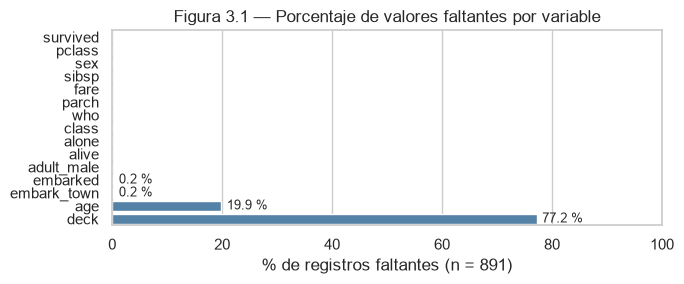

In [6]:
fig, ax = plt.subplots(figsize=(7, 3))
pct = (df.isna().mean() * 100).sort_values()
sns.barplot(x=pct.values, y=pct.index, ax=ax, color="steelblue")
for i, v in enumerate(pct.values):
    if v > 0:
        ax.text(v + 1, i, f"{v:.1f} %", va="center", fontsize=9)
ax.set(xlabel="% de registros faltantes (n = 891)", ylabel="", xlim=(0, 100),
       title="Figura 3.1 — Porcentaje de valores faltantes por variable")
plt.tight_layout()
plt.show()

**Interpretación.**
- **`deck` (77,2 % faltante).** Solo 203 pasajeros tienen cubierta registrada. Con tan poca información, cualquier conclusión sobre la cubierta es frágil, y la imputación no es razonable. Lo más probable es que el faltante no sea aleatorio: el registro de camarotes se conservó sobre todo para la primera clase. Esto se verificará en la sección IV.
- **`age` (19,9 % faltante, 714 válidos).** Afecta directamente a **P2** y a `who`. Todo cálculo sobre la edad debe informar que usa 714 observaciones. **D6:** en esta fase no se imputa; los 177 registros sin edad se conservan para los análisis que no dependen de ella.
- **`embarked` / `embark_town` (2 registros, 0,2 %).** El impacto es despreciable. Los dos faltantes son los mismos registros en ambas columnas (se verifica en III.4.3).
- Las variables de **P3** (`survived`, `sex`, `pclass`) están **completas**, así que P3 puede responderse con los 891 pasajeros.

#### III.4.2 Dominios y rangos

**Qué y por qué.** Se comprueba que cada variable tome solo valores admisibles: categorías esperadas, rangos plausibles y ningún negativo. Si hubiera valores fuera de dominio serían errores, y habría que corregirlos antes de describir distribuciones.

In [7]:
dominios = {
    "survived": {0, 1},
    "pclass": {1, 2, 3},
    "sex": {"male", "female"},
    "embarked": {"C", "Q", "S"},
    "deck": set("ABCDEFG"),
    "who": {"man", "woman", "child"},
}
filas = []
for col, permitidos in dominios.items():
    obs = df[col].dropna()
    filas.append({
        "variable": col,
        "dominio esperado": ", ".join(map(str, sorted(permitidos))),
        "valores observados": ", ".join(map(str, sorted(obs.unique()))),
        "fuera de dominio": int((~obs.isin(permitidos)).sum()),
    })

rangos = {"age": (0, 100), "fare": (0, 600), "sibsp": (0, 10), "parch": (0, 10)}
for col, (lo, hi) in rangos.items():
    obs = df[col].dropna()
    filas.append({
        "variable": col,
        "dominio esperado": f"[{lo}, {hi}]",
        "valores observados": f"mín {obs.min():g} · máx {obs.max():g}",
        "fuera de dominio": int((~obs.between(lo, hi)).sum()),
    })

tabla_dominios = pd.DataFrame(filas).set_index("variable")
tabla_dominios

,dominio esperado,valores observados,fuera de dominio
variable,,,
survived,"0, 1","0, 1",0
pclass,"1, 2, 3","1, 2, 3",0
sex,"female, male","female, male",0
embarked,"C, Q, S","C, Q, S",0
deck,"A, B, C, D, E, F, G","A, B, C, D, E, F, G",0
who,"child, man, woman","child, man, woman",0
age,"[0, 100]",mín 0.42 · máx 80,0
fare,"[0, 600]",mín 0 · máx 512.329,0
sibsp,"[0, 10]",mín 0 · máx 8,0


*Tabla 3.5 — Verificación de dominios categóricos y rangos numéricos.*

In [8]:
edad = df["age"].dropna()
casos_especiales = pd.Series({
    "Tarifa igual a 0": int((df["fare"] == 0).sum()),
    "Edad < 1 año (fraccionaria, en meses)": int((edad < 1).sum()),
    "Edad ≥ 1 terminada en ,5 (edad estimada)": int(((edad >= 1) & (edad % 1 == 0.5)).sum()),
    "Tarifa > 500": int((df["fare"] > 500).sum()),
}, name="registros")
casos_especiales.to_frame()

,registros
Tarifa igual a 0,15
"Edad < 1 año (fraccionaria, en meses)",7
"Edad ≥ 1 terminada en ,5 (edad estimada)",18
Tarifa > 500,3


*Tabla 3.6 — Casos especiales dentro del dominio, que no son errores pero conviene registrar.*

**Interpretación.**
- **Ninguna variable presenta valores fuera de dominio.** Las categorías y los rangos son válidos.
- Hay tres casos que no son errores, pero sí afectan la lectura de **P2**:
  - **15 tarifas iguales a 0.** Son plausibles (pasajes de cortesía o de personal de la naviera), pero bajan la media de `fare`. Se mantienen y se señalarán al describir la tarifa.
  - **Edades fraccionarias.** Según la documentación original del dataset, las edades menores de 1 año se expresan en fracción y las edades terminadas en ,5 son **estimadas** (18 casos). Se aceptan como válidas, con la salvedad de que la edad tiene cierta imprecisión.
  - **Tarifas mayores a 500** (3 registros con 512,33). Son valores extremos reales de primera clase, no errores. Anticipan una distribución de `fare` muy asimétrica (ver IV).

#### III.4.3 Consistencia de variables redundantes y derivadas

**Qué y por qué.** Si dos columnas representan la misma información, deben coincidir siempre. Si no coinciden, hay un error de registro. Además, conviene saber cómo se construyeron las columnas derivadas para no tomarlas como evidencia independiente.

In [9]:
es_adulto_hombre = df["who"].eq("man")
verificaciones = pd.Series({
    "pclass ↔ class (1/2/3 = First/Second/Third)":
        (df["pclass"].map({1: "First", 2: "Second", 3: "Third"}) == df["class"].astype(str)).all(),
    "survived ↔ alive (1/0 = yes/no)":
        (df["survived"].map({1: "yes", 0: "no"}) == df["alive"]).all(),
    "embarked ↔ embark_town (C/Q/S)":
        (df["embarked"].map({"C": "Cherbourg", "Q": "Queenstown", "S": "Southampton"})
         .fillna("NA") == df["embark_town"].fillna("NA")).all(),
    "adult_male ↔ who == 'man'":
        (df["adult_male"] == es_adulto_hombre).all(),
    "alone ↔ sibsp + parch == 0":
        (df["alone"] == (df["sibsp"] + df["parch"]).eq(0)).all(),
}, name="consistente")
verificaciones.to_frame()

,consistente
pclass ↔ class (1/2/3 = First/Second/Third),True
survived ↔ alive (1/0 = yes/no),True
embarked ↔ embark_town (C/Q/S),True
adult_male ↔ who == 'man',True
alone ↔ sibsp + parch == 0,True


*Tabla 3.7a — Coincidencia entre pares de variables redundantes o derivadas.*

In [10]:
who_por_edad = pd.crosstab(
    df["age"].isna().map({True: "edad faltante", False: "edad registrada"}),
    df["who"],
    margins=True, margins_name="Total",
)
who_por_edad

who,child,man,woman,Total
age,,,,
edad faltante,0,124,53,177
edad registrada,83,413,218,714
Total,83,537,271,891


*Tabla 3.7b — Categoría `who` según si la edad está registrada.*

**Interpretación.**
- Los cinco pares redundantes o derivados son **100 % consistentes**. No hay contradicciones, y los 2 faltantes de `embarked` coinciden con los de `embark_town`.
- `class`, `alive` y `embark_town` repiten exactamente la información de `pclass`, `survived` y `embarked`. **D5:** se marcan como redundantes, pero **no se eliminan todavía**. `df_raw` debe seguir íntegro, y la sección V decidirá cuáles retirar de la copia de trabajo.
- **Hallazgo relevante para P3 y para cualquier análisis con `who`.** Los 177 pasajeros sin edad aparecen clasificados como `man` (124) o `woman` (53), nunca como `child`. Es decir, `who` **asume que los pasajeros sin edad son adultos**. Algunos niños pueden estar mal clasificados, así que `who` y `adult_male` no deben usarse como sustituto de la edad. Se registra como limitación.

#### III.4.4 Registros repetidos

**Qué y por qué.** Una fila repetida podría ser un error de carga, y en ese caso inflaría los conteos de P3. Pero este dataset **no tiene identificador único** (no incluye nombre, ticket ni `PassengerId`). Antes de eliminar registros, hay que revisar si las coincidencias pueden corresponder a personas distintas con atributos iguales.

In [11]:
duplicados = df[df.duplicated(keep=False)]
resumen_dup = pd.Series({
    "Filas idénticas a otra anterior (duplicated)": int(df.duplicated().sum()),
    "Filas que participan en algún grupo repetido": len(duplicados),
    "% de esas filas con algún faltante (age o deck)": round(duplicados.isna().any(axis=1).mean() * 100, 1),
    "% de esas filas en 3.ª clase": round(duplicados["pclass"].eq(3).mean() * 100, 1),
}, name="valor", dtype=object)
display(resumen_dup.to_frame())

grupos_dup = (
    duplicados.groupby(list(df.columns), dropna=False, observed=True)
    .size().rename("repeticiones").sort_values(ascending=False).reset_index()
)
grupos_dup[["survived", "pclass", "sex", "age", "sibsp", "parch", "fare", "embarked", "deck", "repeticiones"]].head(8)

,valor
Filas idénticas a otra anterior (duplicated),107
Filas que participan en algún grupo repetido,160
% de esas filas con algún faltante (age o deck),98.80
% de esas filas en 3.ª clase,78.10


,survived,pclass,sex,age,sibsp,parch,fare,embarked,deck,repeticiones
0,0,3,male,NaN,0,0,7.90,S,NaN,13
1,0,3,male,NaN,0,0,8.05,S,NaN,12
2,0,3,male,NaN,0,0,7.75,Q,NaN,8
3,1,3,female,NaN,0,0,7.75,Q,NaN,7
4,0,2,male,NaN,0,0,0.00,S,NaN,6
5,0,3,male,NaN,0,0,7.22,C,NaN,5
6,0,3,male,NaN,0,0,7.23,C,NaN,5
7,0,3,male,NaN,8,2,69.55,S,NaN,4


*Tabla 3.8a — Magnitud de los registros repetidos. Tabla 3.8b — Combinaciones más repetidas.*

**Interpretación y decisión.**
- Hay **107 filas idénticas a otra anterior**, que forman grupos con un total de 160 filas.
- Casi todas (~99 %) tienen la edad o la cubierta sin registrar y corresponden sobre todo a hombres de 3.ª clase que viajaban solos.
- Las tarifas son estándar y se repiten mucho en ese segmento: 7,90, 8,05 y 7,75 libras.

Sin nombre ni ticket, las coincidencias se explican porque el dataset **omite las columnas que distinguirían a esas personas**, no por una duplicación de carga. Por eso, **D4:** **no se eliminan** los registros repetidos, de acuerdo con el supuesto S1. Eliminarlos quitaría 107 pasajeros reales (12 % de la muestra), concentrados en 3.ª clase, y sesgaría P3. Se registra como limitación: con este dataset no es posible verificar la unicidad de los pasajeros.

#### III.4.5 Resumen del diagnóstico de calidad (P1)

In [12]:
resumen_calidad = pd.DataFrame(
    [
        ["Completitud", "deck", "688 faltantes (77,2 %)", "Alto: no apta para conclusiones", "Analizar solo como presencia/ausencia; sin imputar (V)"],
        ["Completitud", "age", "177 faltantes (19,9 %)", "Medio: P2 usa n = 714", "D6: sin imputar en esta fase; informar n válidos"],
        ["Completitud", "embarked / embark_town", "2 faltantes (0,2 %)", "Bajo", "Excluir solo en análisis por puerto"],
        ["Validez", "todas", "0 valores fuera de dominio", "Ninguno", "Sin acción"],
        ["Validez", "fare", "15 tarifas = 0; 3 > 500", "Medio en P2 (asimetría)", "Mantener; usar mediana y escala adecuada (IV)"],
        ["Validez", "age", "18 edades estimadas (,5)", "Bajo", "Mantener; registrar imprecisión"],
        ["Consistencia", "class, alive, embark_town", "100 % redundantes", "Ninguno (sin contradicciones)", "D5: marcar; decidir retiro en V"],
        ["Consistencia", "who / adult_male", "Edad faltante → siempre adulto", "Medio: posible mala clasificación", "No usar como sustituto de age"],
        ["Unicidad", "fila completa", "107 filas repetidas", "Medio: sin ID no verificable", "D4: conservar (personas distintas)"],
    ],
    columns=["dimensión", "variable", "hallazgo", "impacto en el análisis", "decisión / acción"],
)
resumen_calidad.index = resumen_calidad.index + 1
resumen_calidad

,dimensión,variable,hallazgo,impacto en el análisis,decisión / acción
1,Completitud,deck,"688 faltantes (77,2 %)",Alto: no apta para conclusiones,Analizar solo como presencia/ausencia; sin imp...
2,Completitud,age,"177 faltantes (19,9 %)",Medio: P2 usa n = 714,D6: sin imputar en esta fase; informar n válidos
3,Completitud,embarked / embark_town,"2 faltantes (0,2 %)",Bajo,Excluir solo en análisis por puerto
4,Validez,todas,0 valores fuera de dominio,Ninguno,Sin acción
5,Validez,fare,15 tarifas = 0; 3 > 500,Medio en P2 (asimetría),Mantener; usar mediana y escala adecuada (IV)
6,Validez,age,"18 edades estimadas (,5)",Bajo,Mantener; registrar imprecisión
7,Consistencia,"class, alive, embark_town",100 % redundantes,Ninguno (sin contradicciones),D5: marcar; decidir retiro en V
8,Consistencia,who / adult_male,Edad faltante → siempre adulto,Medio: posible mala clasificación,No usar como sustituto de age
9,Unicidad,fila completa,107 filas repetidas,Medio: sin ID no verificable,D4: conservar (personas distintas)


*Tabla 3.9 — Resumen del diagnóstico de calidad: evidencia para P1.*

### III.5 Síntesis de la sección III

- El dataset se cargó de forma reproducible: la fuente está verificada con SHA-256, hay una copia congelada y `df_raw` se mantiene intacto. Tiene **891 pasajeros y 15 variables**, de las cuales solo **9 aportan información independiente**.
- **Respuesta preliminar a P1.** La calidad es buena en validez y consistencia: no hay valores fuera de dominio ni contradicciones. Los problemas están en la **completitud** (`deck` casi inutilizable; `age` con 20 % faltante, lo que condiciona P2) y en la **unicidad**, que no se puede verificar por falta de identificador. Las variables de P3 están completas.
- Las decisiones D1–D6 están identificadas y se consolidan en la sección V. La sección IV continúa con la exploración de P2 y P3 sobre `df`.

## IV. Exploración preliminar

> **Pendiente — Bloque 2 (Sebastián).** Contenido esperado:
> - Resúmenes descriptivos iniciales (P2: `age` con n = 714 válidos, `fare` incluyendo las 15 tarifas en 0 y los extremos > 500).
> - Revisión preliminar de las variables relevantes para P3 (`survived`, `sex`, `pclass`).
> - Visualizaciones numeradas (Figura 4.x) con el número de observaciones válidas y una interpretación tras cada salida.
> - Verificar si el faltante de `deck` se concentra en alguna clase (ver III.4.1).

## V. Decisiones y transformaciones iniciales

### V.1 Registro de decisiones exploratorias

| Id | Decisión | Motivo | Resultado intermedio | Sección |
|---|---|---|---|---|
| D1 | Usar el dataset `titanic` | Es el único que cubre faltantes, redundancias, repetidos y un resultado binario para el análisis bivariado | Dataset de 891 × 15 con todos los componentes de la fase | II.5 |
| D2 | Cargar con `sns.load_dataset` y verificar la fuente con SHA-256 y una copia congelada | La fuente remota puede cambiar; la carga debe ser idéntica en cada ejecución | Huella `81787d32…` verificada; `data/raw/titanic_seaborn.csv` | III.2 |
| D3 | Conservar `df_raw` intacto y trabajar sobre `df` | Mantener trazable la relación entre los datos de entrada y los transformados | `df_raw` sin cambios en todo el notebook | III.2 |
| D4 | No eliminar las 107 filas repetidas | Sin identificador, corresponden a pasajeros distintos con atributos iguales; eliminarlas sesgaría P3 | Se mantienen las 891 filas | III.4.4 |
| D5 | Marcar `class`, `alive` y `embark_town` como redundantes sin borrarlas aún | Son 100 % consistentes con `pclass`, `survived` y `embarked`; el retiro se decide en V | 15 columnas, 9 con información independiente | III.4.3 |
| D6 | No imputar `age` en esta fase | El 19,9 % faltante condiciona P2; imputar sin explorar antes introduciría supuestos no verificados | P2 se calcula con n = 714 y se conservan las 177 filas | III.4.1 |

> **Pendiente — Bloque 2 (Sebastián).** Continuar el registro (D7…) con las transformaciones implementadas: qué se decidió, por qué y qué resultado intermedio produjo (cifras antes/después). Si se excluyen faltantes de `age`, informar cuántos registros quedan fuera y conservarlos para los demás análisis.

## VI. Resultados e interpretación inicial

> **Pendiente — Bloque 2 (Sebastián).** Cerrar P1, P2 y P3 con tablas o figuras numeradas (Tabla 6.x / Figura 6.x). Para P3, informar pasajeros, sobrevivientes y tasa por sexo, por clase y por sexo × clase. Interpretar las diferencias como asociaciones descriptivas (S3) y señalar los grupos pequeños.

## VII. Supuestos y limitaciones

> **Pendiente — Bloque 3 (Yerko).** Consolidar los supuestos S1–S4 (II.4) y las limitaciones detectadas (III.4: `deck` 77 % faltante, `age` 20 % faltante, `who` asume adultos, unicidad no verificable, muestra de 891), indicando qué análisis condiciona cada una y qué queda pendiente para fases posteriores.

## VIII. Cierre del avance

> **Pendiente — Bloque 3 (Yerko).** Síntesis del trabajo realizado, principales hallazgos de la fase y continuidad prevista para las siguientes etapas del proyecto.